# Flight Price Prediction

**Portfolio notebook | Regression | Python, pandas, scikit-learn**

**Goal:** Predict flight ticket prices from flight details such as airline,
source, destination, departure time, flight duration, and the number of stops.

**What this version improves:** Reproducible relative paths, a clear problem
statement, leakage-safe preprocessing, baseline comparisons, cross-validation,
Random Forest tuning, error analysis, and honest model limitations.

**Data requirement:** Download or supply the original `Data_Train.xlsx` and
place it under `data/`. The dataset was not included with the provided
notebook. The saved outputs were generated on the supplied historical 2019 dataset.
Run all cells again to independently reproduce the results.

**Important:** The previous notebook used target-dependent category encodings
before splitting the data. This version intentionally replaces them with
One-Hot Encoding fitted within a scikit-learn Pipeline on training data only.

## 1. Setup and reproducibility

Run the notebook from the project root or from the `notebooks/` folder.
Install dependencies with `python -m pip install -r requirements.txt`.
No local Windows paths, unsafe `eval`, or pickled model loads are required.

In [1]:
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error, mean_absolute_percentage_error,
    mean_squared_error, r2_score,
)
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "requirements.txt").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_FILE = PROJECT_ROOT / "data" / "Data_Train.xlsx"
MODEL_FILE = PROJECT_ROOT / "models" / "flight_price_model.joblib"
RANDOM_STATE = 42

print("Project directory:", PROJECT_ROOT.resolve())
import sys
sys.path.insert(0, str(PROJECT_ROOT.resolve()))
from src.flight_features import make_features, CATEGORICAL, NUMERIC


Project directory: /workspace/scratch/27ecd818c658/Flight_Price_Prediction_Improved


## 2. Load data and define the prediction target

**Target:** `Price` (the original fare currency in the dataset).
Do not change genuine high prices into the median: doing so changes the
problem being evaluated. Investigate suspicious prices before deciding
whether any rows are actually erroneous.

In [2]:
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Missing {DATA_FILE}. Place the original Data_Train.xlsx in the data folder."
    )

raw = pd.read_excel(DATA_FILE)
required = {
    "Airline", "Source", "Destination", "Date_of_Journey", "Dep_Time",
    "Arrival_Time", "Duration", "Total_Stops", "Additional_Info", "Price",
}
missing_columns = required.difference(raw.columns)
if missing_columns:
    raise ValueError(f"Missing dataset columns: {sorted(missing_columns)}")

raw["Price"] = pd.to_numeric(raw["Price"], errors="coerce")
raw = raw.dropna(subset=["Price"]).copy()
print("Rows:", len(raw), "Columns:", len(raw.columns))
display(raw.head())
display(raw.isna().sum().sort_values(ascending=False).to_frame("missing_values"))

Rows: 10683 Columns: 11


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


,missing_values
Route,1
Total_Stops,1
Airline,0
Source,0
Date_of_Journey,0
Dep_Time,0
Destination,0
Arrival_Time,0
Duration,0
Additional_Info,0


## 3. Hold out the test set before learning from data

The test set is used only once, after model selection and hyperparameter
tuning. All statistics-based preprocessing (imputation, scaling, encoding)
will be fitted **inside a Pipeline** using training folds only.

In [3]:
X_raw = raw.drop(columns=["Price"])
y = raw["Price"].astype(float)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.25, random_state=RANDOM_STATE
)
print("Training rows:", len(X_train_raw), "Test rows:", len(X_test_raw))

Training rows: 8012 Test rows: 2671


## 4. Feature engineering

These transformations are deterministic and process each flight independently:

- Journey day, month, and weekday from `Date_of_Journey`.
- Departure and arrival hour/minute from time strings.
- Duration converted to total minutes without `eval`.
- Stops converted to an ordinal number, e.g. `non-stop` -> 0.

We omit `Route` to keep the model compact and avoid redundant route detail.
Missing or unfamiliar values are dealt with later by the fitted preprocessors.

In [4]:
# Shared with the deployed app: identical row-level feature engineering.
from src.flight_features import make_features, CATEGORICAL, NUMERIC
X_train = make_features(X_train_raw)
X_test = make_features(X_test_raw)
display(X_train.head())

,Airline,Source,Destination,Additional_Info,journey_day,journey_month,journey_weekday,departure_hour,departure_minute,arrival_hour,arrival_minute,duration_minutes,total_stops
752,IndiGo,Delhi,Cochin,No info,27,5,0,16,0,21,0,300,1
7431,SpiceJet,Chennai,Kolkata,No info,6,5,0,8,20,10,35,135,0
5478,Jet Airways,Kolkata,Banglore,No info,12,6,2,18,55,19,50,1495,1
3445,Jet Airways,Delhi,Cochin,No info,6,6,3,11,30,4,25,1015,1
9380,Jet Airways,Banglore,Delhi,No info,18,6,1,7,10,10,10,180,0


## 5. Exploratory data analysis on training data

EDA is shown on the training portion so that test-set information does
not drive feature selection or modeling decisions. Check price distribution,
missingness, airline differences, and duration relationships.

,count,median,mean
Airline,,,
Jet Airways,2870,11507.0,11682.758885
IndiGo,1567,4990.0,5664.007020
Air India,1310,9692.0,9660.470992
Multiple carriers,892,10197.0,10879.830717
SpiceJet,606,3873.0,4347.372937
Vistara,364,7980.0,7680.887363
Air Asia,234,5162.0,5575.730769
GoAir,149,5281.0,6047.771812
Multiple carriers Premium economy,13,11269.0,11418.846154


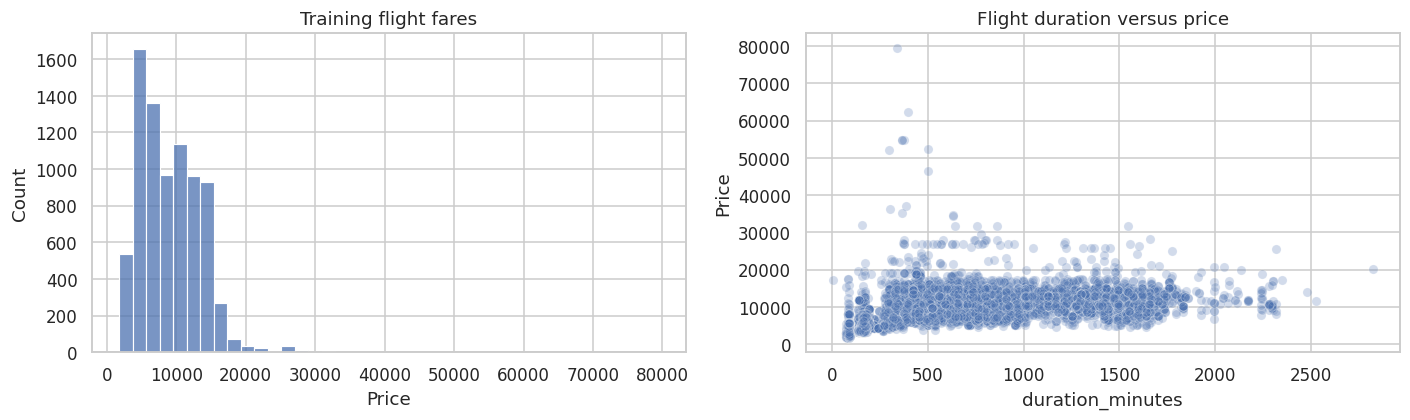

In [5]:
train_eda = X_train.copy()
train_eda["Price"] = y_train
display(train_eda.groupby("Airline")["Price"].agg(["count", "median", "mean"]).sort_values("count", ascending=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(train_eda["Price"], bins=40, ax=ax[0])
ax[0].set_title("Training flight fares")
sns.scatterplot(data=train_eda, x="duration_minutes", y="Price", alpha=0.25, ax=ax[1])
ax[1].set_title("Flight duration versus price")
plt.tight_layout()

## 6. Leakage-safe preprocessing and baseline models

The `ColumnTransformer` is fitted separately within every training fold.
`OneHotEncoder` is used instead of price-based category encoding.
We compare a simple median baseline, a regularized linear model (Ridge),
and Random Forest using the same 3-fold cross-validation on training data.
MAE is the selection metric because it is expressed in the same fare units.

In [6]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, NUMERIC),
    ("categorical", categorical_pipeline, CATEGORICAL),
])

def pipeline(model):
    return Pipeline([("preprocess", preprocessor), ("model", model)])

candidates = {
    "Median baseline": pipeline(DummyRegressor(strategy="median")),
    "Ridge regression": pipeline(Ridge(alpha=10.0)),
    "Random Forest": pipeline(RandomForestRegressor(
        n_estimators=180, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1,
    )),
}
cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
records = []
for label, estimator in candidates.items():
    scores = cross_validate(
        estimator, X_train, y_train, cv=cv,
        scoring={"mae": "neg_mean_absolute_error", "r2": "r2"}, n_jobs=1,
    )
    records.append({
        "model": label,
        "cv_MAE": -scores["test_mae"].mean(),
        "cv_R2": scores["test_r2"].mean(),
    })
comparison = pd.DataFrame(records).sort_values("cv_MAE")
display(comparison)

,model,cv_MAE,cv_R2
2,Random Forest,751.889878,0.868207
1,Ridge regression,1801.702306,0.647258
0,Median baseline,3627.952975,-0.025479


## 7. Tune Random Forest using training data only

`RandomizedSearchCV` fits the preprocessing pipeline separately within
each cross-validation fold. The test set remains untouched.

In [7]:
search = RandomizedSearchCV(
    estimator=pipeline(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
    param_distributions={
        "model__n_estimators": [150, 250, 350],
        "model__max_depth": [None, 10, 18, 26],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", 0.8, 1.0],
    },
    n_iter=12, cv=cv, random_state=RANDOM_STATE,
    scoring="neg_mean_absolute_error", n_jobs=-1, refit=True, verbose=0,
)
search.fit(X_train, y_train)
print("Best Random Forest CV MAE:", round(-search.best_score_, 2))
print("Best hyperparameters:", search.best_params_)

Best Random Forest CV MAE: 747.58
Best hyperparameters: {'model__n_estimators': 150, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 1.0, 'model__max_depth': 18}


## 8. Select the final model, then evaluate ONCE on test data

Choose a model using training cross-validation MAE only. Refit the
selected model on the complete training set (the tuned estimator is
already refitted by `RandomizedSearchCV`). Evaluate on test data once.
Do not change the model after looking at these scores.

In [8]:
cv_mae = {row["model"]: row["cv_MAE"] for _, row in comparison.iterrows()}
cv_mae["Tuned Random Forest"] = -search.best_score_
winner = min(cv_mae, key=cv_mae.get)
if winner == "Tuned Random Forest":
    final_model = search.best_estimator_
else:
    final_model = candidates[winner].fit(X_train, y_train)

test_predictions = final_model.predict(X_test)
test_results = {
    "selected_model": winner,
    "MAE": mean_absolute_error(y_test, test_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, test_predictions)),
    "R2": r2_score(y_test, test_predictions),
    "MAPE_percent": 100 * mean_absolute_percentage_error(y_test, test_predictions),
}
print(pd.Series(test_results, name="Final test result"))
print("These are the NEW results; do not reuse scores from the original notebook.")

selected_model    Tuned Random Forest
MAE                        664.467185
RMSE                      1530.602811
R2                           0.885313
MAPE_percent                 7.598285
Name: Final test result, dtype: object
These are the NEW results; do not reuse scores from the original notebook.


### Additional robustness check: exact duplicate flights across the split

Some raw feature rows occur in both training and test data. A random split
can therefore make performance look better if the model memorizes those rows.
After selecting the final model, we also report its error on **test examples
whose complete raw input feature row does not appear in training**. This is
not a substitute for a chronological or group-based validation design; it is
a transparent post-hoc sensitivity check and is not used for model tuning.


In [9]:
# Post-selection sensitivity check: exact duplicate input rows across the split.
# This is diagnostic only; it is not used to select or re-tune the model.
train_fingerprints = set(pd.util.hash_pandas_object(
    X_train_raw.astype("string").fillna("<NA>"), index=False
))
test_fingerprints = pd.util.hash_pandas_object(
    X_test_raw.astype("string").fillna("<NA>"), index=False
)
novel_mask = ~test_fingerprints.isin(train_fingerprints)
print("Test examples with identical raw features in train:", int((~novel_mask).sum()))
print("Test examples without identical raw features in train:", int(novel_mask.sum()))
print("MAE on non-overlapping test examples:", round(mean_absolute_error(
    y_test[novel_mask], test_predictions[novel_mask.to_numpy()]), 2))
print("R² on non-overlapping test examples:", round(r2_score(
    y_test[novel_mask], test_predictions[novel_mask.to_numpy()]), 4))


Test examples with identical raw features in train: 157
Test examples without identical raw features in train: 2514
MAE on non-overlapping test examples: 653.03
R² on non-overlapping test examples: 0.8867


## 9. Error analysis and model interpretation

Examine which airlines and price ranges are hardest to predict. The
following diagnostic plots use the final test predictions for reporting
only; do not tune the model based on these plots without creating a new
untouched evaluation set.

,count,mean
airline,,
Jet Airways Business,1,33014.158690
Vistara Premium economy,2,1415.223657
GoAir,45,1291.283406
Multiple carriers,304,1187.672573
Air India,442,1004.224793
Air Asia,85,757.458521
Vistara,115,517.361497
Jet Airways,979,496.003066
IndiGo,486,425.406695


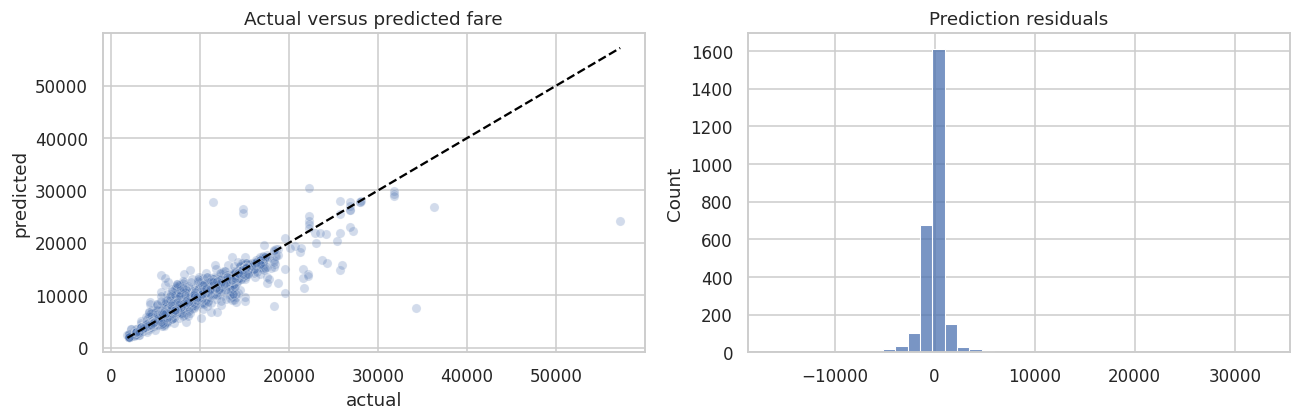

In [10]:
diagnostic = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "predicted": np.asarray(test_predictions),
    "airline": X_test_raw["Airline"].to_numpy(),
})
diagnostic["absolute_error"] = abs(diagnostic["actual"] - diagnostic["predicted"])
display(diagnostic.groupby("airline")["absolute_error"].agg(["count", "mean"]).sort_values("mean", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=diagnostic, x="actual", y="predicted", alpha=0.25, ax=axes[0])
low = min(diagnostic["actual"].min(), diagnostic["predicted"].min())
high = max(diagnostic["actual"].max(), diagnostic["predicted"].max())
axes[0].plot([low, high], [low, high], color="black", linestyle="--")
axes[0].set_title("Actual versus predicted fare")
sns.histplot(diagnostic["actual"] - diagnostic["predicted"], bins=40, ax=axes[1])
axes[1].set_title("Prediction residuals")
plt.tight_layout()

In [11]:
# Optional: importance of ORIGINAL engineered features, not one-hot columns.
# Use these as final diagnostics, not as a reason to re-tune on the test set.
importance = permutation_importance(
    final_model, X_test, y_test, n_repeats=3,
    scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=-1,
)
feature_importance = pd.Series(
    importance.importances_mean, index=X_test.columns
).sort_values(ascending=False)
display(feature_importance.to_frame("permutation_importance"))

,permutation_importance
Airline,1824.089079
duration_minutes,1789.909447
journey_month,861.967964
Additional_Info,657.722460
journey_day,497.277292
total_stops,437.735957
Source,264.425749
Destination,254.379923
departure_minute,205.261440
arrival_hour,186.520315


## 10. Save the entire fitted preprocessing + model pipeline

For new flights, first apply the same **deterministic** `make_features`
function, then call the saved Pipeline's `predict`. The function `make_features` lives in `src/flight_features.py` and is
shared by training and the Streamlit application, ensuring consistent inference. Load serialized models **only from
trusted sources**.

In [12]:
MODEL_FILE.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(final_model, MODEL_FILE)
print("Saved model pipeline to:", MODEL_FILE)

# Smoke example using known input rows; no fictional input categories.
example_raw_flights = X_test_raw.head(3).copy()
example_features = make_features(example_raw_flights)
print("Example predictions:", final_model.predict(example_features))

Saved model pipeline to: /workspace/scratch/27ecd818c658/Flight_Price_Prediction_Improved/models/flight_price_model.joblib
Example predictions: [11102.2097381   5632.58056349 14502.27175063]


## 11. Limitations and next steps

- The original data reflects historical fares; actual market prices are
  affected by booking lead time, demand, seasonality, and changing airline
  policies, which are not fully represented in these features.
- Random train/test splitting estimates performance on similar data from
  the same period. A chronological split is worth testing if the goal is
  **future** price forecasting.
- Prediction error should be compared with business requirements. Large
  errors on expensive tickets may matter more than average MAE suggests.
- More robust target encoding is possible using cross-fitting, but simple
  one-hot encoding is preferable here until properly validated.
- To make this a deployable service, add automated tests, a validated input
  schema, and an application that calls the exact same preprocessing logic.
- Do not present pre-refactoring R2, MAE or RMSE as the new model's results.

## 12. Interview preparation prompts

1. Why did you choose Random Forest over a single Decision Tree?
2. Why does target-guided encoding before splitting cause data leakage?
3. Why did you choose MAE for model selection, and what does RMSE add?
4. What is the difference between training CV and final test evaluation?
5. How did you create time and duration features without using the target?
6. What does a negative R2 mean, and why is the median baseline useful?
7. How would you deal with new airlines that were absent in training?
8. When might a chronological split be more realistic than a random split?
9. Why did you avoid replacing expensive tickets with the median?
10. How would you explain model limitations to a non-technical stakeholder?